# 04 — Optimisation : preuves, robustesse et décision
**Projet Data Mining — Prédiction du départ des employés (Employee Attrition)**

Le réglage des hyperparamètres (`GridSearchCV` / `RandomizedSearchCV`, validation croisée à 5 plis, métrique = average precision) est réalisé dans le notebook 03. Ce notebook en **démontre l'intérêt et les limites**, et prolonge l'optimisation vers la décision.

| § | Question | Méthode |
|---|---|---|
| 1 | Que gagne-t-on par rapport aux hyperparamètres par défaut ? | comparaison à plis identiques (CV et test) |
| 2 | Grille complète ou recherche aléatoire : quel coût pour quel résultat ? | simulation sur les scores déjà calculés |
| 3 | Les scores de validation croisée sont-ils optimistes ? | **validation croisée imbriquée** (5 plis externes, réglage sur 3 plis internes) |
| 4 | Une sélection de variables, réglée dans la CV, aide-t-elle ? | `SelectKBest` dans le `Pipeline`, k réglé par CV, 2 critères |
| 5 | À quel seuil faut-il alerter selon le coût d'une intervention ? | analyse coût-bénéfice sur probabilités calibrées |

In [1]:
import sys, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.models import *
from src.evaluation import *
from src.optimization import *

PROC, FIG = ROOT / "data" / "processed", ROOT / "reports" / "figures"
BLUE, ORANGE, GREY = "#8fb8de", "#d9822b", "#9a9a9a"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = lambda x: f"{x:.4f}"
pd.options.display.width = 230
pd.options.display.max_colwidth = 80
def savefig(name): plt.savefig(FIG / name, dpi=150, bbox_inches="tight")

X_train = pd.read_csv(PROC / "X_train_raw.csv"); X_test = pd.read_csv(PROC / "X_test_raw.csv")
y_train = pd.read_csv(PROC / "y_train.csv").squeeze("columns"); y_test = pd.read_csv(PROC / "y_test.csv").squeeze("columns")
OPT_DIR.mkdir(parents=True, exist_ok=True)

templates = get_searches()                                   # recherches non ajustées
searches = {n: fit_search(n, s, X_train, y_train) for n, s in templates.items()}   # résultats en cache (notebook 03)
print("recherches rechargées :", list(searches))

recherches rechargées : ['K-NN', 'Arbre de décision', 'Random Forest', 'Naive Bayes (Gaussian)', 'Naive Bayes (Bernoulli)', 'SVM', 'Régression logistique', 'Gradient Boosting', 'K-NN (cosinus)', 'Extra Trees', 'AdaBoost', 'Bagging', 'Sélection de variables', 'XGBoost']


---
# 1. Gain apporté par l'optimisation des hyperparamètres
Pour chaque modèle : mêmes plis, même prétraitement, mêmes poids de classes. Seule change la valeur des hyperparamètres : **valeurs par défaut de scikit-learn** contre **valeurs optimisées**. La performance est mesurée en validation croisée (AP) et sur le test (AP et ROC-AUC).

In [2]:
p = OPT_DIR / "defaut_vs_optimise.csv"
if not p.exists(): default_vs_tuned(searches, X_train, y_train, X_test, y_test).to_csv(p)
dvt = pd.read_csv(p, index_col=0)
dvt[["AP_cv_défaut", "AP_cv_optimisé", "gain_AP_cv", "AP_test_défaut", "AP_test_optimisé", "gain_AP_test", "ROC_test_défaut", "ROC_test_optimisé"]]

,AP_cv_défaut,AP_cv_optimisé,gain_AP_cv,AP_test_défaut,AP_test_optimisé,gain_AP_test,ROC_test_défaut,ROC_test_optimisé
modèle,,,,,,,,
K-NN,0.1036,0.1568,0.0532,0.1014,0.1691,0.0677,0.5328,0.6511
Arbre de décision,0.0930,0.1456,0.0526,0.0920,0.1369,0.0450,0.5077,0.6083
Random Forest,0.1309,0.1691,0.0382,0.1264,0.1630,0.0366,0.5750,0.6550
Naive Bayes (Gaussian),0.1383,0.1424,0.0041,0.1411,0.1435,0.0024,0.6168,0.6254
Naive Bayes (Bernoulli),0.1583,0.1615,0.0032,0.1563,0.1520,-0.0042,0.6424,0.6341
SVM,0.1260,0.1499,0.0238,0.1292,0.1576,0.0285,0.6017,0.6554
Régression logistique,0.1512,0.1525,0.0013,0.1517,0.1595,0.0078,0.6505,0.6564
Gradient Boosting,0.1302,0.1729,0.0427,0.1410,0.1732,0.0322,0.6016,0.6648


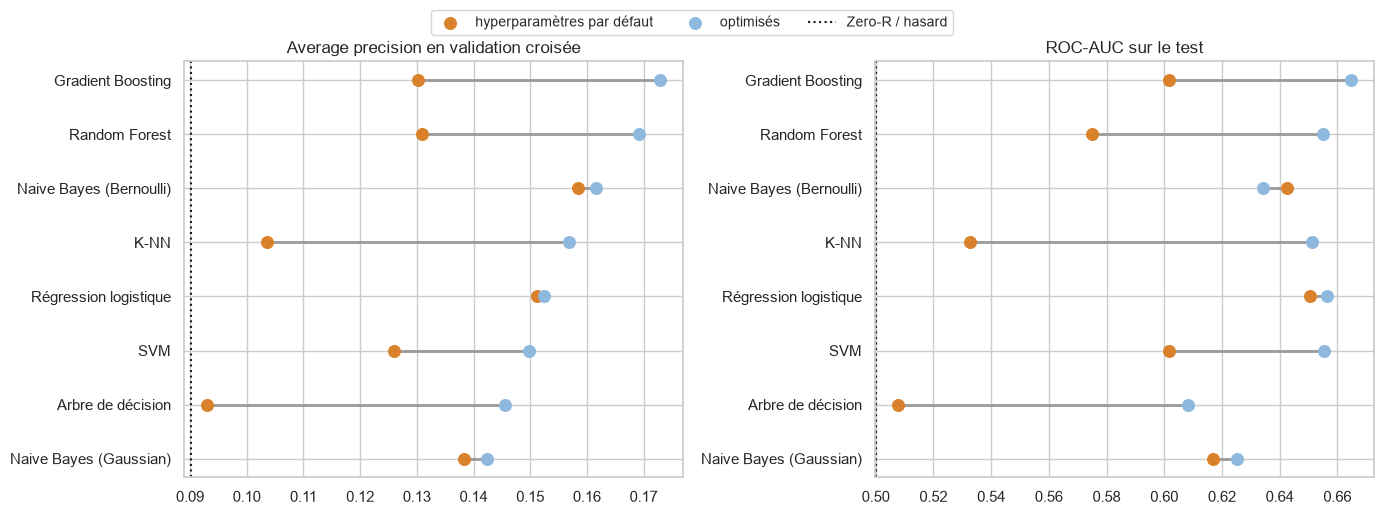

In [3]:
order = dvt.sort_values("AP_cv_optimisé").index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
y_pos = np.arange(len(order))
for ax, (c0, c1, ttl, ref) in zip(axes, [("AP_cv_défaut", "AP_cv_optimisé", "Average precision en validation croisée", y_train.mean()),
                                         ("ROC_test_défaut", "ROC_test_optimisé", "ROC-AUC sur le test", 0.5)]):
    ax.hlines(y_pos, dvt.loc[order, c0], dvt.loc[order, c1], color=GREY, lw=2)
    ax.scatter(dvt.loc[order, c0], y_pos, color=ORANGE, s=70, label="hyperparamètres par défaut", zorder=3)
    ax.scatter(dvt.loc[order, c1], y_pos, color=BLUE, s=70, label="optimisés", zorder=3)
    ax.axvline(ref, color="k", ls=":", label="Zero-R / hasard")
    ax.set_yticks(y_pos); ax.set_yticklabels(order); ax.set_title(ttl)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04), fontsize=10)
plt.tight_layout(); savefig("24_defaut_vs_optimise.png"); plt.show()

**Interprétation.**
- L'optimisation est **indispensable pour les modèles sensibles à leurs hyperparamètres** : K-NN (AP en CV 0,104 → 0,157 ; ROC-AUC test 0,533 → 0,651), arbre de décision (0,093 → 0,146 ; ROC 0,508 → 0,608), Gradient Boosting (+0,043), Random Forest (+0,038) et SVM (+0,024). Avec les réglages par défaut, K-NN (K = 5) et l'arbre non élagué **mémorisent du bruit** et ne valent guère mieux que le hasard (ROC-AUC de 0,53 et 0,51) ; la régularisation (K = 800, feuilles de ≥ 100 individus…) les rend utiles.
- Pour **Naïve Bayes** et la **régression logistique**, le gain est nul ou négligeable (+0,001 à +0,004 d'AP en CV ; BernoulliNB est même un peu moins bon sur le test, −0,004, dans le bruit) : peu d'hyperparamètres influents.
- Gains en CV et sur le test vont **dans le même sens** : l'optimisation ne sur-ajuste pas la validation croisée.

---
# 2. Grille complète ou recherche aléatoire ?
`RandomizedSearchCV` tire *n* configurations au hasard au lieu de tester toute la grille. Plutôt que de relancer des recherches, on **simule** ce tirage à partir des scores déjà calculés par la grille complète (5 000 tirages sans remise par cas). `p_proche` = probabilité de trouver une configuration à moins de 0,002 d'AP de l'optimum (≪ écart-type de validation de ~0,01). La Random Forest (déjà aléatoire) est exclue.

In [4]:
gvr = random_search_simulation(searches)
gvr.to_csv(OPT_DIR / "grid_vs_random.csv", index=False)
cost = gvr.drop_duplicates("modèle").set_index("modèle")[["configurations_grille", "secondes_grille_complète"]]
cost

,configurations_grille,secondes_grille_complète
modèle,,
K-NN,36,62.2210
Arbre de décision,144,32.0524
Naive Bayes (Gaussian),11,2.2228
Naive Bayes (Bernoulli),18,3.5581
SVM,22,153.2209
Régression logistique,5,1.1763
Gradient Boosting,81,80.5434
K-NN (cosinus),5,30.3971
AdaBoost,9,80.9172


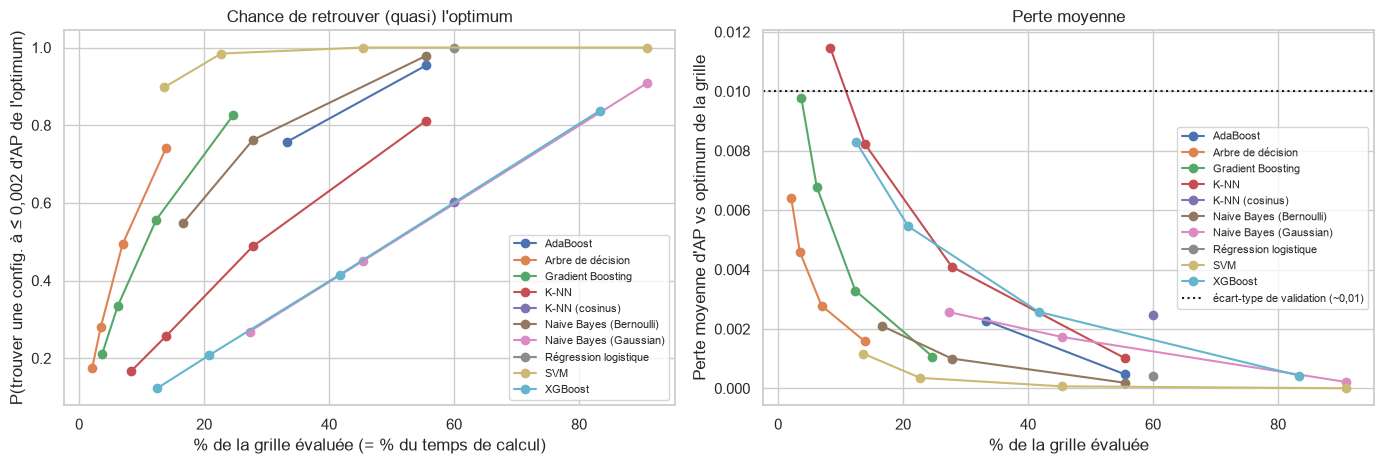

,configurations_grille,part_du_calcul,perte_moyenne,p_proche
modèle,,,,
K-NN,36,0.2778,0.0041,0.4878
Arbre de décision,144,0.0694,0.0028,0.4936
Naive Bayes (Gaussian),11,0.9091,0.0002,0.9088
Naive Bayes (Bernoulli),18,0.5556,0.0002,0.9790
SVM,22,0.4545,0.0001,1.0000
Gradient Boosting,81,0.1235,0.0033,0.5568
XGBoost,24,0.4167,0.0026,0.4148


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, g in gvr.groupby("modèle"):
    axes[0].plot(g.part_du_calcul * 100, g.p_proche, marker="o", label=name)
    axes[1].plot(g.part_du_calcul * 100, g.perte_moyenne, marker="o", label=name)
axes[0].set_xlabel("% de la grille évaluée (= % du temps de calcul)"); axes[0].set_ylabel("P(trouver une config. à ≤ 0,002 d'AP de l'optimum)")
axes[0].set_title("Chance de retrouver (quasi) l'optimum"); axes[0].legend(fontsize=8)
axes[1].axhline(0.01, color="k", ls=":", label="écart-type de validation (~0,01)")
axes[1].set_xlabel("% de la grille évaluée"); axes[1].set_ylabel("Perte moyenne d'AP vs optimum de la grille"); axes[1].set_title("Perte moyenne"); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("25_grid_vs_random.png"); plt.show()
gvr[gvr.tirages == 10][["modèle", "configurations_grille", "part_du_calcul", "perte_moyenne", "p_proche"]].set_index("modèle")

**Interprétation.** Les paysages d'AP sont **plats** : beaucoup de configurations sont presque aussi bonnes que la meilleure. Avec **10 tirages** (7 % du calcul pour l'arbre, 12 % pour Gradient Boosting, 28 % pour K-NN), la perte moyenne d'AP n'est que de 0,003 à 0,004, soit environ **trois fois moins que l'écart-type de validation (~0,01)**, et la probabilité de retrouver une configuration à ≤ 0,002 de l'optimum est d'environ 50 % (≈ 75 à 83 % avec 20 tirages). Pour le SVM, **3 tirages** (14 % du calcul, soit ~21 s sur 153 s) suffisent dans 90 % des cas. `RandomizedSearchCV` est donc le bon choix pour les **grandes grilles** (justifie son usage pour la Random Forest) ; `GridSearchCV` reste préférable pour les **petites grilles** (< 20 configurations : Naïve Bayes, régression logistique), où l'exhaustivité coûte quelques secondes.

---
# 3. Validation croisée imbriquée : le score de la CV est-il optimiste ?
Quand on choisit la meilleure configuration parmi des dizaines **avec les mêmes plis** qui servent à la noter, son score est biaisé à la hausse (biais de sélection). La **validation croisée imbriquée** l'élimine : boucle externe (5 plis, graine différente) pour *évaluer*, boucle interne (3 plis) pour *régler*. Le réglage ne voit jamais le pli externe de test. *Réserve : la boucle interne n'a que 3 plis (coût de calcul), ce qui pénalise légèrement le score imbriqué.*

In [6]:
p = OPT_DIR / "validation_imbriquee.csv"
order_n = ["Naive Bayes (Gaussian)", "Naive Bayes (Bernoulli)", "Régression logistique", "Arbre de décision", "K-NN", "Random Forest", "Gradient Boosting", "SVM"]
nested = run_nested(templates, searches, X_train, y_train, p, names=order_n)     # reprend le calcul s'il a été interrompu
nested[["AP_cv_non_imbriqué", "AP_imbriqué", "AP_imbriqué_std", "optimisme", "ROC_imbriqué", "secondes"]].sort_values("AP_imbriqué", ascending=False)

,AP_cv_non_imbriqué,AP_imbriqué,AP_imbriqué_std,optimisme,ROC_imbriqué,secondes
modèle,,,,,,
Gradient Boosting,0.1729,0.1682,0.0189,0.0048,0.6580,234.2617
Naive Bayes (Bernoulli),0.1615,0.1657,0.0205,-0.0041,0.6443,11.7574
Random Forest,0.1691,0.1644,0.0161,0.0048,0.6553,216.7963
Régression logistique,0.1525,0.1517,0.0142,0.0008,0.6360,4.2724
K-NN,0.1568,0.1514,0.0130,0.0054,0.6397,414.9848
SVM,0.1499,0.1499,0.0109,-0.0000,0.6357,290.3959
Naive Bayes (Gaussian),0.1424,0.1430,0.0193,-0.0006,0.6105,8.0935
Arbre de décision,0.1456,0.1394,0.0127,0.0061,0.6297,162.6012


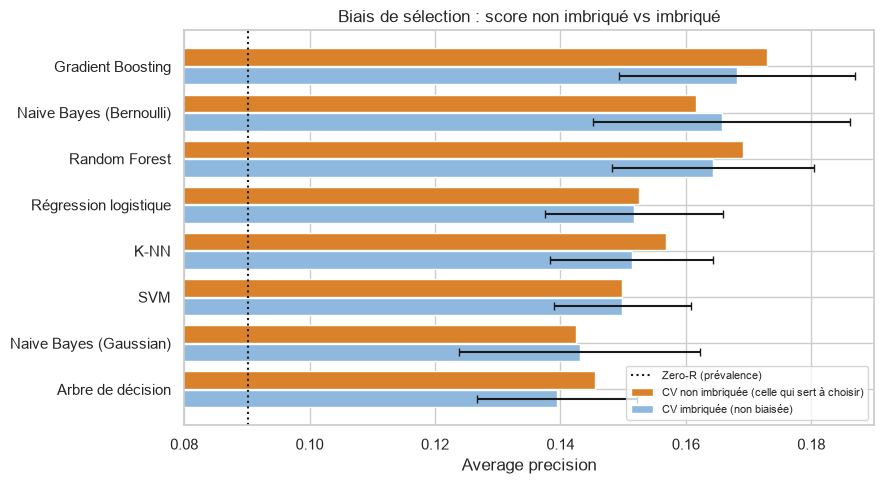

optimisme moyen = 0.0021  | écart-type de validation typique = 0.0157


In [7]:
nn = nested.sort_values("AP_imbriqué")
fig, ax = plt.subplots(figsize=(9, 5))
yy = np.arange(len(nn))
ax.barh(yy + 0.2, nn["AP_cv_non_imbriqué"], height=0.38, color=ORANGE, label="CV non imbriquée (celle qui sert à choisir)")
ax.barh(yy - 0.2, nn["AP_imbriqué"], xerr=nn["AP_imbriqué_std"], height=0.38, color=BLUE, capsize=3, label="CV imbriquée (non biaisée)")
ax.axvline(y_train.mean(), color="k", ls=":", label="Zero-R (prévalence)")
ax.set_yticks(yy); ax.set_yticklabels(nn.index); ax.set_xlim(0.08, 0.19); ax.set_xlabel("Average precision")
ax.set_title("Biais de sélection : score non imbriqué vs imbriqué"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); savefig("26_validation_imbriquee.png"); plt.show()
print(f"optimisme moyen = {nested['optimisme'].mean():.4f}  | écart-type de validation typique = {nested['AP_imbriqué_std'].mean():.4f}")

**Interprétation.** Le biais de sélection est **faible** : 0,002 d'AP en moyenne (de −0,004 à +0,006), bien en dessous de l'écart-type de validation (0,011 à 0,021). Il est le plus marqué pour les modèles les plus flexibles (arbre +0,006, K-NN +0,005, Gradient Boosting et Random Forest +0,005) et nul pour les modèles peu flexibles (SVM, régression logistique, Naïve Bayes ; les écarts négatifs de Naïve Bayes sont du bruit). Les scores de la validation croisée du notebook 03 sont donc **fiables à ≈ 0,005 près**. Le classement est confirmé (Gradient Boosting 0,168, BernoulliNB 0,166, Random Forest 0,164 > régression logistique 0,152, K-NN 0,151, SVM 0,150 > GaussianNB 0,143 > arbre 0,139) ; les écarts entre les trois premiers restent inférieurs à l'écart-type. Le score imbriqué de Gradient Boosting (0,168 ± 0,019) est cohérent avec son AP sur le test (0,173).

---
# 4. Sélection de variables réglée dans la validation croisée
L'EDA et les importances montrent que le signal tient dans quelques variables. Les modèles sensibles au bruit (K-NN, Naïve Bayes gaussien, SVM, régression logistique) pourraient gagner à ignorer les autres. On insère un `SelectKBest` **dans le `Pipeline`** (il est réappris à chaque pli : pas de fuite) et on règle **k** par validation croisée, hyperparamètres du modèle fixés à leur valeur optimale. Deux critères de classement sont comparés :
- **F de l'ANOVA** : test paramétrique rapide, stable.
- **Information mutuelle** : non paramétrique, mais estimation bruitée quand le signal est faible.

Règle retenue pour choisir k : le **plus petit k dont l'AP est à moins d'un écart-type du meilleur** (règle de l'écart-type : le modèle le plus simple statistiquement équivalent).

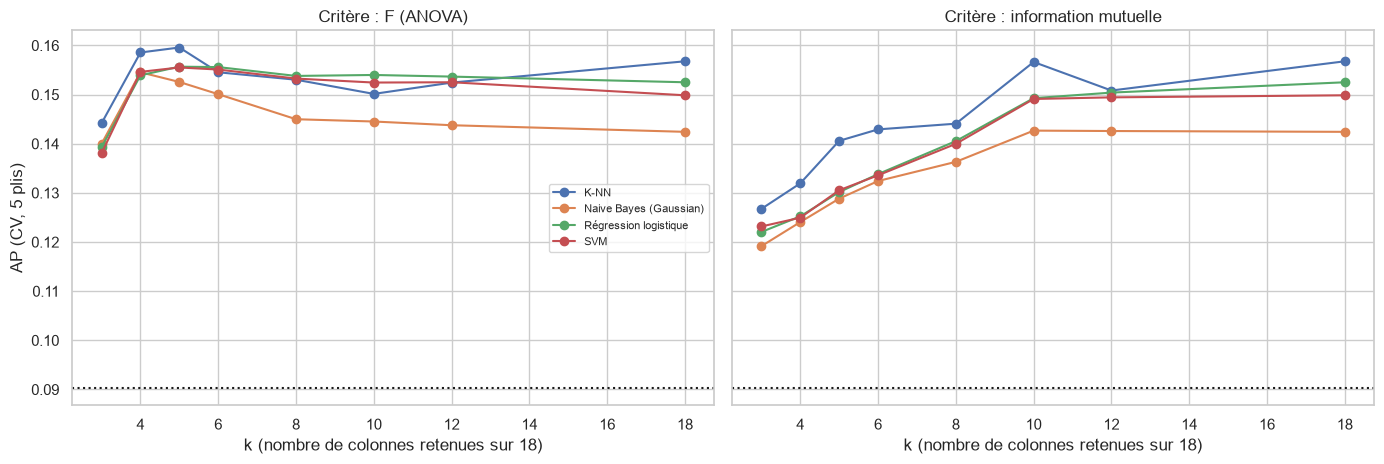

In [8]:
pc, ps = OPT_DIR / "selection_variables_courbe.csv", OPT_DIR / "selection_variables_resume.csv"
if not (pc.exists() and ps.exists()):
    curve, summ = feature_selection_study(searches, X_train, y_train, X_test, y_test)
    curve.to_csv(pc, index=False); summ.to_csv(ps)
curve = pd.read_csv(pc); summ = pd.read_csv(ps, index_col=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, crit in zip(axes, curve["critère"].unique()):
    for name, g in curve[curve["critère"] == crit].groupby("modèle"):
        ax.plot(g.k, g.AP_cv, marker="o", label=name)
    ax.axhline(y_train.mean(), color="k", ls=":"); ax.set_title(f"Critère : {crit}"); ax.set_xlabel("k (nombre de colonnes retenues sur 18)")
axes[0].set_ylabel("AP (CV, 5 plis)"); axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("27_selection_variables.png"); plt.show()

In [9]:
summ[["k_retenu", "AP_cv_sans_sélection", "AP_cv_avec_sélection", "AP_test_sans", "AP_test_avec", "ROC_test_sans", "ROC_test_avec", "ΔROC_test", "ΔROC_p"]]

k_retenu  AP_cv_sans_sélection  AP_cv_avec_sélection  AP_test_sans  AP_test_avec  ROC_test_sans  ROC_test_avec  ΔROC_test  ΔROC_p
modèle                 critère                                                                                                                                                
K-NN                   F (ANOVA)                    4                0.1568                0.1586        0.1691        0.1621         0.6511         0.6468    -0.0042  0.8260
                       information mutuelle        10                0.1568                0.1566        0.1691        0.1669         0.6511         0.6540     0.0030  0.7040
Naive Bayes (Gaussian) F (ANOVA)                    4                0.1424                0.1545        0.1435        0.1587         0.6254         0.6534     0.0280  0.0520
                       information mutuelle         5                0.1424                0.1288        0.1435        0.1419         0.6254         0.6251    -0.0003  0.9580
SVM                    F (ANOVA)                    4                0.1499                0.1546        0.1576        0.1627         0.6554         0.6581     0.0027  0.6540
                       information mutuelle         8                0.1499                0.1400        0.1576        0.1643         0.6554         0.6542    -0.0012  0.8840
Régression logistique  F (ANOVA)                    4                0.1525                0.1539        0.1595        0.1623         0.6564         0.6574     0.0011  0.8340
                       information mutuelle         8                0.1525                0.1405        0.1595        0.1634         0.6564         0.6547    -0.0016  0.8020

In [10]:
summ["variables_retenues"].to_frame()

variables_retenues
modèle                 critère                                                                                              
K-NN                   F (ANOVA)                                        JobLevel, JobSatisfaction, WorkLifeBalance, OverTime
                       information mutuelle  Age, YearsAtCompany, JobLevel, JobSatisfaction, WorkLifeBalance, OverTime, P...
Naive Bayes (Gaussian) F (ANOVA)                                        JobLevel, JobSatisfaction, WorkLifeBalance, OverTime
                       information mutuelle                  Age, YearsAtCompany, JobLevel, JobSatisfaction, WorkLifeBalance
SVM                    F (ANOVA)                                        JobLevel, JobSatisfaction, WorkLifeBalance, OverTime
                       information mutuelle  Age, YearsAtCompany, JobLevel, JobSatisfaction, WorkLifeBalance, OverTime, D...
Régression logistique  F (ANOVA)                                        JobLevel, JobSatisfaction, WorkLifeBalance, OverTime
                       information mutuelle  Age, YearsAtCompany, JobLevel, JobSatisfaction, WorkLifeBalance, OverTime, D...

**Interprétation.**
- **Le critère compte.** L'information mutuelle, estimation bruitée quand le signal est faible, retient des variables sans intérêt (indicatrices de département) et **dégrade l'AP en CV** pour Naïve Bayes (0,142 → 0,129), SVM (0,150 → 0,140) et régression logistique (0,153 → 0,141). Le F de l'ANOVA retient pour les quatre modèles les mêmes 4 variables : `JobLevel`, `JobSatisfaction`, `WorkLifeBalance`, `OverTime`.
- Avec ces **4 variables sur 18**, les modèles font **aussi bien** qu'avec toutes : AP en CV de 0,154 à 0,159 contre 0,142 à 0,157 (gain de +0,001 à +0,012, dans l'écart-type de ~0,01). Sur le test, les écarts de ROC-AUC sont ≤ 0,03 et **aucun n'est significatif** (p ≥ 0,05). Seul GaussianNB en profite nettement en CV (0,142 → 0,155), logiquement : c'est lui qui souffre le plus des variables redondantes et non gaussiennes.
- **Conclusion** : la sélection n'améliore pas la performance de façon démontrable, mais elle montre que **4 variables suffisent** : modèle plus simple, formulaire plus court pour l'application, moins de données à collecter. Elle ne rattrape pas le Gradient Boosting (AP en CV 0,173).

---
# 5. Optimisation de la décision : à quel seuil alerter ?
Le notebook 03 choisit le seuil qui maximise le F1. Mais ce critère ignore les coûts. Avec des **probabilités calibrées** (§ 11.2 du notebook 03), la décision optimale est simple :

> Alerter un employé si le gain espéré de l'intervention dépasse son coût : **p × R > 1**, soit **seuil = 1 / R**,

où **R = taux de succès de l'intervention × coût d'un départ / coût de l'intervention** (en pratique : « combien d'interventions un départ évité permet-il de payer ? »). Un seul paramètre métier, R, fixe le seuil. Ici, les unités sont relatives (coût d'une intervention = 1). Évaluation sur le **test** : seuil choisi par la théorie, pas ajusté sur le test.

In [11]:
bundle = load_bundle()
p_test = bundle["model"].predict_proba(X_test)[:, 1]
prev = y_test.mean()
print(f"modèle : {bundle['name']} | taux de base = {prev:.1%} | probabilité max sur le test = {p_test.max():.1%} | seuil F1 = {bundle['threshold']:.3f} (⇔ R = {1 / bundle['threshold']:.1f})")
print(f"R à partir duquel alerter TOUT LE MONDE devient rentable : 1/prévalence = {1 / prev:.1f}")
dec = decision_table(y_test, p_test)
dec.to_csv(OPT_DIR / "decision_cout_benefice.csv")
dec

modèle : Gradient Boosting | taux de base = 9.0% | probabilité max sur le test = 35.9% | seuil F1 = 0.118 (⇔ R = 8.5)
R à partir duquel alerter TOUT LE MONDE devient rentable : 1/prévalence = 11.0


,seuil_optimal,alertes,départs_ciblés,précision,rappel,bénéfice_modèle,bénéfice_alerter_tous,bénéfice_ne_rien_faire,gain_vs_sans_modèle
R,,,,,,,,,
3.0000,0.3333,4,0,0.0000,0.0000,-2.0000,-728.5000,0.0000,-2.0000
5.0000,0.2000,85,23,0.2706,0.1271,15.0000,-547.5000,0.0000,15.0000
8.5000,0.1176,460,81,0.1761,0.4475,114.2500,-230.7500,0.0000,114.2500
12.0000,0.0833,922,124,0.1345,0.6851,283.0000,86.0000,0.0000,197.0000
15.0000,0.0667,1218,145,0.1190,0.8011,478.5000,357.5000,0.0000,121.0000
20.0000,0.0500,1645,166,0.1009,0.9171,837.5000,810.0000,0.0000,27.5000
30.0000,0.0333,1882,178,0.0946,0.9834,1729.0000,1715.0000,0.0000,14.0000
50.0000,0.0200,2000,181,0.0905,1.0000,3525.0000,3525.0000,0.0000,0.0000


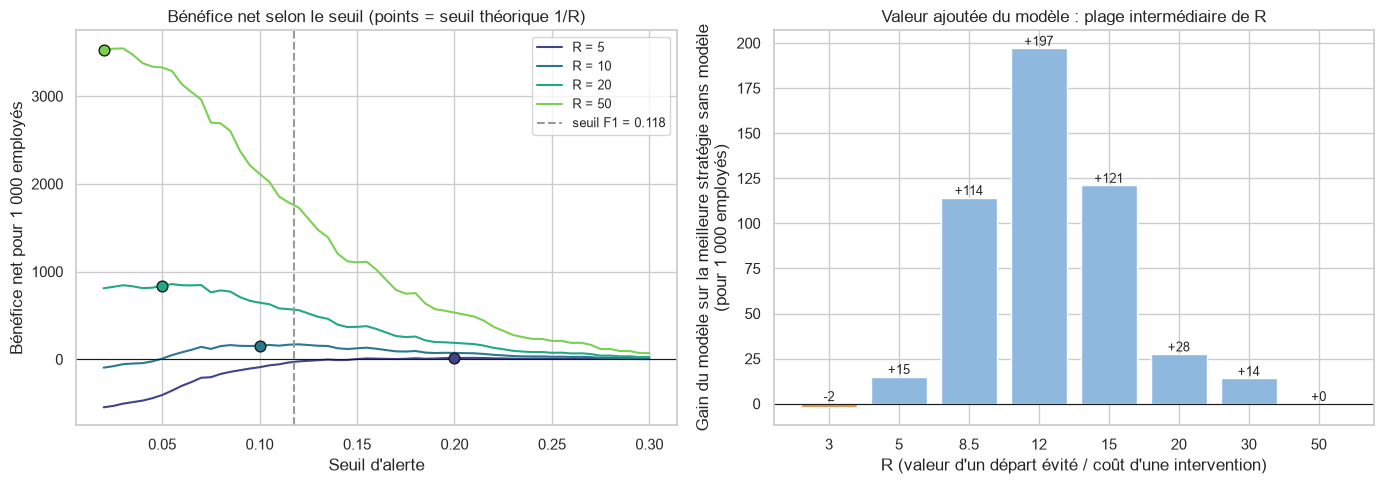

In [12]:
thr_grid = np.linspace(0.02, 0.30, 57)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for R, col in zip((5, 10, 20, 50), sns.color_palette("viridis", 4)):
    nb_ = [net_benefit_per_1000(y_test, p_test, t, R) for t in thr_grid]
    axes[0].plot(thr_grid, nb_, color=col, label=f"R = {R}")
    axes[0].scatter([1 / R], [net_benefit_per_1000(y_test, p_test, 1 / R, R)], color=col, zorder=3, s=60, edgecolor="k")
axes[0].axhline(0, color="k", lw=.8); axes[0].axvline(bundle["threshold"], color=GREY, ls="--", label=f"seuil F1 = {bundle['threshold']:.3f}")
axes[0].set_xlabel("Seuil d'alerte"); axes[0].set_ylabel("Bénéfice net pour 1 000 employés")
axes[0].set_title("Bénéfice net selon le seuil (points = seuil théorique 1/R)"); axes[0].legend(fontsize=9)

g = dec["gain_vs_sans_modèle"]
bars = axes[1].bar([f"{r:g}" for r in g.index], g.values, color=[BLUE if v > 0 else ORANGE for v in g.values])
for b_, v in zip(bars, g.values):
    axes[1].annotate(f"{v:+.0f}", (b_.get_x() + b_.get_width() / 2, max(v, 0)), ha="center", va="bottom", fontsize=9)
axes[1].axhline(0, color="k", lw=.8)
axes[1].set_xlabel("R (valeur d'un départ évité / coût d'une intervention)")
axes[1].set_ylabel("Gain du modèle sur la meilleure stratégie sans modèle\n(pour 1 000 employés)")
axes[1].set_title("Valeur ajoutée du modèle : plage intermédiaire de R")
plt.tight_layout(); savefig("28_decision_cout_benefice.png"); plt.show()

**Interprétation.**
- Le seuil F1 du notebook 03 (0,118) correspond implicitement à **R ≈ 8,5** : un départ évité vaudrait 8,5 interventions. C'est une hypothèse métier cachée ; le bon seuil dépend du vrai rapport coût/bénéfice de l'entreprise.
- **R ≤ 5 : le modèle ne sert quasiment à rien.** À R = 3, seuil 0,33, il ne produit que 4 alertes et aucun départ ciblé (−2) ; à R = 5, le gain n'est que de +15 pour 1 000 employés.
- **R de ~8 à ~20 : le modèle est utile.** Il bat à la fois « ne rien faire » et « alerter tout le monde » : à R = 8,5, +114 contre −231 si l'on alerte tout le monde ; à R = 12, +283 contre +86. Le gain sur la meilleure stratégie sans modèle est maximal autour de R ≈ 12 (≈ +200 unités pour 1 000 employés).
- **R ≥ 20 : alerter (presque) tout le monde** devient quasi aussi rentable (810 contre 838 à R = 20) : le seuil 1/R tombe à 5 % ou moins et le modèle n'apporte plus rien.
- Le modèle n'a donc de valeur que dans une **plage intermédiaire** de R, ce qui est cohérent avec un signal faible. *Réserve : ces bénéfices sont estimés sur 181 départs, donc bruités.* Pour l'application : proposer un **curseur de rapport coût/bénéfice** qui fixe le seuil à 1/R, plutôt qu'un seuil fixe.

---
# 6. Synthèse

| Question | Réponse |
|---|---|
| L'optimisation sert-elle ? | **Oui pour K-NN** (AP +0,053 ; ROC-AUC test 0,53 → 0,65), **l'arbre** (+0,053), **Gradient Boosting** (+0,043), **Random Forest** (+0,038), **SVM** (+0,024). Négligeable pour Naïve Bayes et la régression logistique |
| Grille ou recherche aléatoire ? | Paysages plats : 10 tirages (7 à 28 % du calcul des grandes grilles) perdent en moyenne 0,003 à 0,004 d'AP (≪ écart-type 0,01). `RandomizedSearchCV` pour les grandes grilles, `GridSearchCV` pour les petites |
| La CV est-elle optimiste ? | Peu : **0,002 d'AP en moyenne** (max 0,006), bien sous l'écart-type. Classement confirmé ; Gradient Boosting : 0,168 ± 0,019 en validation imbriquée |
| Faut-il sélectionner des variables ? | Pas de gain démontrable (p ≥ 0,05), mais **4 variables suffisent** (`JobLevel`, `JobSatisfaction`, `WorkLifeBalance`, `OverTime`). L'information mutuelle dégrade ; le F de l'ANOVA est neutre à légèrement positif |
| À quel seuil décider ? | **Seuil = 1/R**, avec R = valeur d'un départ évité / coût d'une intervention. Le modèle est utile pour R de ~8 à ~20 (gain maximal ≈ +200 / 1 000 employés vers R ≈ 12) ; hors de cette plage, « ne rien faire » ou « alerter tous » vaut autant |
| Modèle final | **Inchangé** : Gradient Boosting calibré (`models/best_model.joblib`). Le seuil F1 (0,118) équivaut à R ≈ 8,5 ; l'application laissera l'utilisateur choisir R |

**Limites.** (1) Validation imbriquée à 3 plis internes (coût de calcul) : légèrement pessimiste. (2) La simulation de recherche aléatoire réutilise les scores de la grille : elle ne tient pas compte de l'aléa d'un nouveau tirage de plis. (3) L'analyse coût-bénéfice repose sur 181 départs et sur un paramètre R **non observé** : il doit venir du métier.